# 02b - Phase 1a MCQ Generation and Complete Evaluation

This notebook is the visual companion to the completed structured Phase 1a generation run and the subsequent full evaluation pass. It explains **what each generation condition changes** and **how the complete metric contract turns structured distractors into evidence**.

```mermaid
flowchart LR
    A[Structured generation] --> B[Three distractors + paths]
    B --> C[Family 1: answer/reference checks]
    B --> D[Family 2: plausibility]
    B --> E[Family 2: coherence + diversity]
    C --> F[Separate condition comparisons]
    D --> F
    E --> F
```

The notebook does not regenerate distractors. It reads the complete structured generation records and evaluates them with [`scripts/evaluate_phase1_new_metrics.py`](../scripts/evaluate_phase1_new_metrics.py).

## Run snapshot

- **Generation grid:** 11 conditions x 200 held-out Eedi questions x 3 stochastic runs = **6,600 question-runs**
- **Generation model:** Azure GPT-4.1-mini for every condition, including RAG
- **Embedding model:** Azure `text-embedding-3-small-EU`
- **Structured generation:** every successful distractor includes `faulty_step` and ordered `reasoning_steps`
- **Current evaluation:** 19,800 plausibility judgments, 19,800 coherence judgments, 4,109 pathway-pair judgments, and 6,600 LLM-PM records
- **Artifacts:** [`structured_eval_full_v2_20260810`](../experiments/results/phase1_mcq/structured_eval_full_v2_20260810)

The structured source contains 6,600 unique records after retrying 11 initial generation failures. Pathway diversity is conditional: it is summarized over question-runs with at least two incorrect, plausible, coherent distractors, while pathway measurement coverage is reported separately.

In [31]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

PROJECT_ROOT = next(
    candidate
    for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / "scripts" / "run_phase1_mcq.py").exists()
)
sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "experiments" / "results" / "phase1_mcq" / "structured_eval_full_v2_20260810"
AGGREGATED_PATH = RESULTS_DIR / "aggregated.json"
PER_RECORD_PATH = RESULTS_DIR / "per_record.jsonl"
TEST_SET_PATH = PROJECT_ROOT / "data" / "eedi" / "test_set_200.json"

CONDITIONS = [
    "01_basic_direct",
    "02_expert_direct",
    "03_pedagogical_direct",
    "04_expert_cot",
    "05_expert_self_critique",
    "06_lookalike_direct",
    "07_expert_mc_random",
    "08_expert_mc_names",
    "09_expert_mc_causal",
    "10_pedagogical_cot_mc_causal",
    "11_fewshot_rag",
]

FAMILY_COLORS = {
    "Prompting": "#4C78A8",
    "Misconception conditioning": "#F58518",
    "Retrieval": "#54A24B",
}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

print("Project root:", PROJECT_ROOT)
print("Current structured metrics:", RESULTS_DIR)
print("Conditions:", len(CONDITIONS))

Project root: /Users/xuouyu/Desktop/Master Thesis
Current structured metrics: /Users/xuouyu/Desktop/Master Thesis/experiments/results/phase1_mcq/structured_eval_full_v2_20260810
Conditions: 11


In [32]:
with TEST_SET_PATH.open() as handle:
    test_set = json.load(handle)

aggregated = json.loads(AGGREGATED_PATH.read_text())
per_record = [
    json.loads(line)
    for line in PER_RECORD_PATH.read_text().splitlines()
    if line.strip()
]

records = []
for record in per_record:
    incorrectness = record["incorrectness"]
    plausibility = record["student_plausibility"]
    coherence = record["path_coherence"]
    diversity = record["pathway_diversity"]
    pm = record["pm"]
    records.append({
        "condition": record["condition"],
        "question_id": record["question_id"],
        "subject": record.get("subject", ""),
        "run": record["run"],
        "Incorrectness": incorrectness["rate"],
        "IncorrectnessMeasured": incorrectness["rate"] is not None,
        "UnknownRate": incorrectness["unknown"] / record["n_distractors"] if record["n_distractors"] else None,
        "Plausibility": plausibility["mean_score_0_to_2"],
        "PlausibilityScreen": plausibility["screening_rate_ge_1"],
        "Coherence": coherence["rate"],
        "CoherenceMeasured": coherence["status"] == "measured",
        "PathwayDiversity": diversity["value"],
        "PathwayDiversityMeasured": diversity["value"] is not None,
        "PM_raw": pm["raw"],
        "PM_normalized": pm["normalized"],
        "PM_llm": pm["llm"],
        "PM_llmUnknownPairs": pm["llm_unknown_pairs"],
        "output_contract_valid": record["output_contract_valid"],
    })

results_df = pd.DataFrame(records)
aggregate_df = pd.DataFrame([aggregated[condition] for condition in CONDITIONS])
aggregate_df["CoherenceCoverage"] = aggregate_df["path_coherence_measured_question_runs"] / 600
aggregate_df["PathwayDiversityCoverage"] = aggregate_df["pathway_diversity_measured_question_runs"] / 600

expected_keys = {
    (condition, question["QuestionId"], run)
    for condition in CONDITIONS
    for question in test_set
    for run in range(3)
}
observed_keys = set(zip(results_df["condition"], results_df["question_id"], results_df["run"]))
judgment_path = RESULTS_DIR / "plausibility_judgments.jsonl"
judgment_count = sum(1 for line in judgment_path.read_text().splitlines() if line.strip())
print(f"Saved evaluation records: {len(results_df):,} / {len(expected_keys):,}")
print(f"Missing keys: {len(expected_keys - observed_keys)}")
print(f"Duplicate keys: {len(results_df) - len(observed_keys)}")
print(f"Plausibility judgments: {judgment_count:,}")
display(aggregate_df[[
    "condition", "question_runs", "incorrectness_rate", "student_plausibility_mean_0_to_2",
    "path_coherence_rate", "pathway_diversity_mean", "PM_normalized", "PM_llm",
]])

Saved evaluation records: 6,600 / 6,600
Missing keys: 0
Duplicate keys: 0
Plausibility judgments: 19,800


,condition,question_runs,incorrectness_rate,student_plausibility_mean_0_to_2,path_coherence_rate,pathway_diversity_mean,PM_normalized,PM_llm
0,01_basic_direct,600,0.9605,1.4550,0.9267,0.7254,0.2367,0.3711
1,02_expert_direct,600,0.9505,1.4550,0.9322,0.7474,0.2356,0.3639
2,03_pedagogical_direct,600,0.9435,1.4328,0.9333,0.7255,0.2289,0.3617
3,04_expert_cot,600,0.9250,1.3539,0.9178,0.7849,0.2022,0.3322
4,05_expert_self_critique,600,0.9113,1.4222,0.9178,0.7622,0.2383,0.3656
5,06_lookalike_direct,600,0.9430,1.4472,0.9156,0.7595,0.2350,0.3661
6,07_expert_mc_random,600,0.9293,1.2211,0.9444,0.8547,0.1672,0.2683
7,08_expert_mc_names,600,0.8686,1.1406,0.9378,0.8268,0.1683,0.2739
8,09_expert_mc_causal,600,0.9032,1.1756,0.9494,0.8105,0.1706,0.2839
9,10_pedagogical_cot_mc_causal,600,0.8618,1.1289,0.9500,0.8046,0.1672,0.2811


## 1. What each generation method does

The conditions are deliberately grouped by the intervention applied to the generator:

1. **Prompting variants** change the role or reasoning instruction while keeping the question and answer format fixed.
2. **Misconception conditioning** supplies either arbitrary or semantically retrieved Eedi misconception labels, then asks the model to use them when constructing errors.
3. **Few-shot retrieval** supplies similar Eedi questions and their distractors as in-context examples.

The baseline is `02_expert_direct`: an expert role, direct instruction, and no retrieved context. Every comparison should be read against that condition.

,condition,family,system,instruction,context,purpose
0,01_basic_direct,Prompting,basic,direct,zero-shot,Minimal lower-bound role prompt
1,02_expert_direct,Prompting,expert,direct,zero-shot,Expert baseline for all comparisons
2,03_pedagogical_direct,Prompting,pedagogical,direct,zero-shot,Error taxonomy and diagnostic framing
3,04_expert_cot,Prompting,expert,CoT,zero-shot,Enumerate errors before selecting distractors
4,05_expert_self_critique,Prompting,expert,self-critique,zero-shot,"Draft, review, and revise in one prompt"
5,06_lookalike_direct,Prompting,lookalike,direct,zero-shot,Simulate authentic student mistakes
6,07_expert_mc_random,Misconception conditioning,expert,direct,random labels,Control: arbitrary Eedi labels
7,08_expert_mc_names,Misconception conditioning,expert,direct,retrieved names,"Semantic labels, without causal scaffold"
8,09_expert_mc_causal,Misconception conditioning,expert,direct,retrieved + causal,Link each label to a question-specific wrong a...
9,10_pedagogical_cot_mc_causal,Misconception conditioning,pedagogical,CoT,retrieved + causal,"Combined framing, reasoning, and grounding"


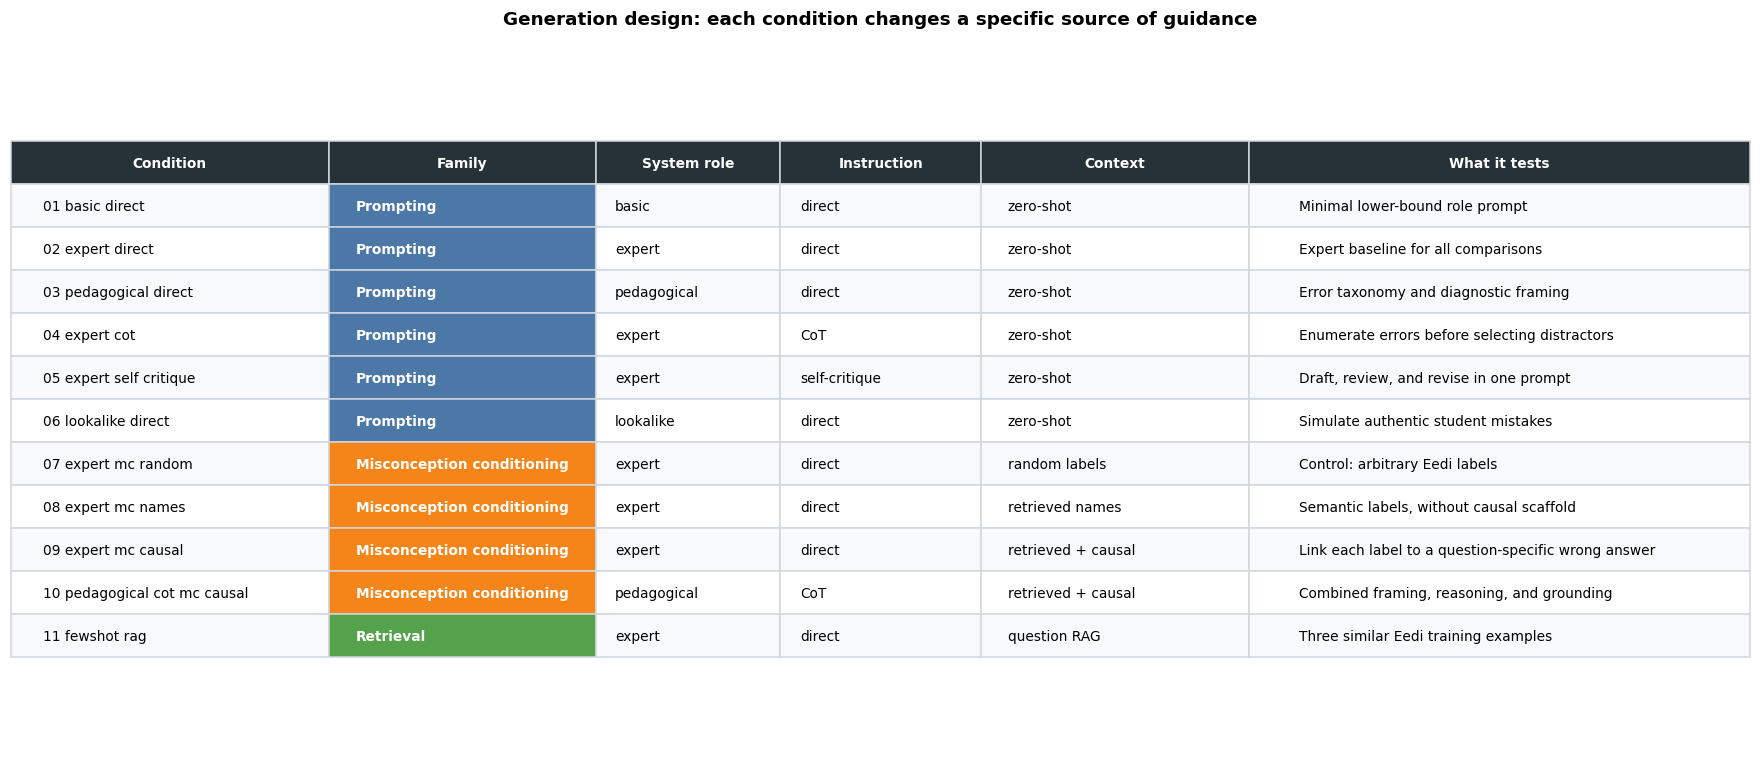

In [27]:
generation_rows = [
    ("01_basic_direct", "Prompting", "basic", "direct", "zero-shot", "Minimal lower-bound role prompt"),
    ("02_expert_direct", "Prompting", "expert", "direct", "zero-shot", "Expert baseline for all comparisons"),
    ("03_pedagogical_direct", "Prompting", "pedagogical", "direct", "zero-shot", "Error taxonomy and diagnostic framing"),
    ("04_expert_cot", "Prompting", "expert", "CoT", "zero-shot", "Enumerate errors before selecting distractors"),
    ("05_expert_self_critique", "Prompting", "expert", "self-critique", "zero-shot", "Draft, review, and revise in one prompt"),
    ("06_lookalike_direct", "Prompting", "lookalike", "direct", "zero-shot", "Simulate authentic student mistakes"),
    ("07_expert_mc_random", "Misconception conditioning", "expert", "direct", "random labels", "Control: arbitrary Eedi labels"),
    ("08_expert_mc_names", "Misconception conditioning", "expert", "direct", "retrieved names", "Semantic labels, without causal scaffold"),
    ("09_expert_mc_causal", "Misconception conditioning", "expert", "direct", "retrieved + causal", "Link each label to a question-specific wrong answer"),
    ("10_pedagogical_cot_mc_causal", "Misconception conditioning", "pedagogical", "CoT", "retrieved + causal", "Combined framing, reasoning, and grounding"),
    ("11_fewshot_rag", "Retrieval", "expert", "direct", "question RAG", "Three similar Eedi training examples"),
]
generation_df = pd.DataFrame(
    generation_rows,
    columns=["condition", "family", "system", "instruction", "context", "purpose"],
)
generation_df["label"] = generation_df["condition"].str.replace("_", " ", regex=False)
display(generation_df[["condition", "family", "system", "instruction", "context", "purpose"]])

fig, ax = plt.subplots(figsize=(16, 7))
ax.axis("off")
table = ax.table(
    cellText=generation_df[["label", "family", "system", "instruction", "context", "purpose"]].values,
    colLabels=["Condition", "Family", "System role", "Instruction", "Context", "What it tests"],
    colWidths=[0.19, 0.16, 0.11, 0.12, 0.16, 0.30],
    cellLoc="left",
    loc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2.0)
for (row_index, col_index), cell in table.get_celld().items():
    cell.set_edgecolor("#D0D7DE")
    if row_index == 0:
        cell.set_facecolor("#263238")
        cell.set_text_props(color="white", weight="bold")
    else:
        family = generation_df.iloc[row_index - 1]["family"]
        cell.set_facecolor("#F7F9FB" if row_index % 2 else "white")
        if col_index == 1:
            cell.set_facecolor(FAMILY_COLORS[family])
            cell.set_text_props(color="white", weight="bold")
ax.set_title("Generation design: each condition changes a specific source of guidance", pad=18, weight="bold")
plt.tight_layout()
plt.show()

## 2. Evaluation families

The current evaluation separates answer/reference alignment from student-error plausibility and pathway behavior. The full structured-metrics run reads 6,600 saved generations; it does not regenerate them.

### Family 1 - answer and reference evaluation

| Metric | How it works | What it measures |
|---|---|---|
| **Incorrectness** | Deterministic checker; reports `incorrect`, `correct`, `unknown`, or `unusable` | Whether the generated option is a usable wrong answer |
| **PM raw** | One-to-one exact string matching | Strict overlap with human Eedi distractors |
| **PM normalized** | One-to-one matching after formatting and case normalization | Reference alignment without formatting noise |
| **LLM-verified PM** | GPT-4.1-mini judges generated-human answer equivalence, then one-to-one matching | Secondary semantic answer alignment; unknown pairs are retained |

Incorrectness is averaged over decisive checks only. Unsupported symbolic or text answers remain `unknown`; they are not turned into a separate plotted coverage metric.

### Family 2 - student-error and pathway evaluation

| Metric | How it works | What it measures |
|---|---|---|
| **Student plausibility** | Independent Azure GPT-4.1-mini judge, score 0-2 per distractor | Whether a middle-school student could plausibly select the option |
| **Screening flag** | Retain `score >= 1` as a broad screening threshold | Fraction passing the permissive plausibility screen |
| **Path coherence** | Judge executes the supplied `reasoning_steps` and compares its result with `text` | Whether the claimed pathway reaches the answer |
| **Pathway diversity** | Pairwise same-faulty-step judgments over incorrect, plausible, coherent paths; connected components become error classes | Whether usable candidates represent distinct error pathways |
| **Functional diversity** | Frozen simulated-student profiles reach different options | PF-specific behavioral instrument; not run in this experiment |

Pathway diversity is reported only when at least two distractors pass incorrectness, plausibility, and coherence. Otherwise it is `not measurable` for that question-run, with pathway measurement coverage reported separately.

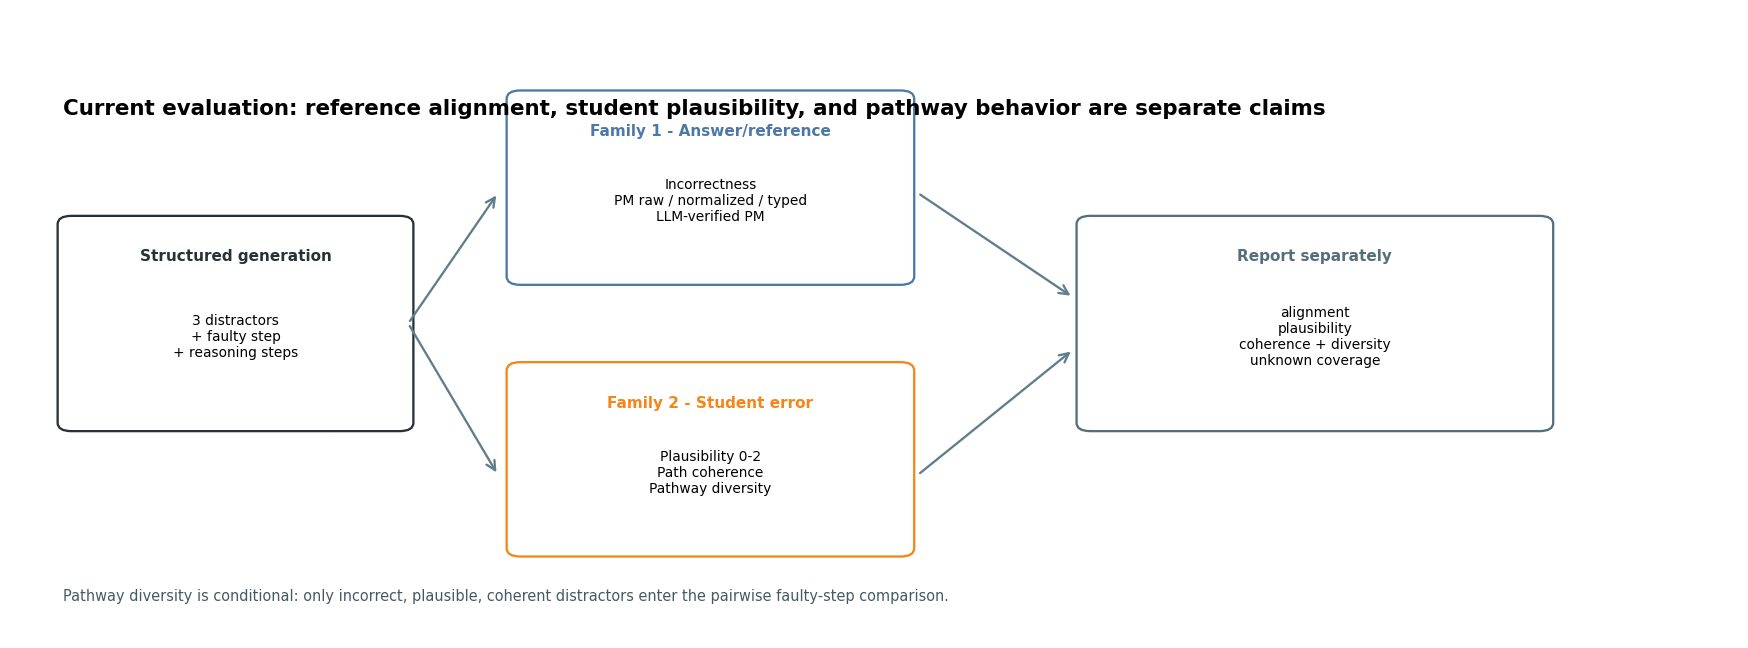

In [28]:
fig, ax = plt.subplots(figsize=(16, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

pipeline = [
    (0.3, 2.0, 2.0, 2.0, "Structured generation", "3 distractors\n+ faulty step\n+ reasoning steps", "#263238"),
    (2.9, 3.4, 2.3, 1.8, "Family 1 - Answer/reference", "Incorrectness\nPM raw / normalized / typed\nLLM-verified PM", "#4C78A8"),
    (2.9, 0.8, 2.3, 1.8, "Family 2 - Student error", "Plausibility 0-2\nPath coherence\nPathway diversity", "#F58518"),
    (6.2, 2.0, 2.7, 2.0, "Report separately", "alignment\nplausibility\ncoherence + diversity\nunknown coverage", "#546E7A"),
]
for x, y, width, height, title, body, color in pipeline:
    patch = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.5,
        edgecolor=color,
        facecolor="white",
    )
    ax.add_patch(patch)
    ax.text(x + width / 2, y + height - 0.28, title, ha="center", va="top", weight="bold", color=color, fontsize=10)
    ax.text(x + width / 2, y + height / 2 - 0.12, body, ha="center", va="center", fontsize=9)

for start, end in [((2.3, 3.0), (2.82, 4.25)), ((2.3, 3.0), (2.82, 1.55)), ((5.25, 4.25), (6.15, 3.25)), ((5.25, 1.55), (6.15, 2.75))]:
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="->", mutation_scale=15, linewidth=1.5, color="#607D8B"))

ax.text(0.3, 5.0, "Current evaluation: reference alignment, student plausibility, and pathway behavior are separate claims", fontsize=14, weight="bold")
ax.text(0.3, 0.35, "Pathway diversity is conditional: only incorrect, plausible, coherent distractors enter the pairwise faulty-step comparison.", fontsize=9.5, color="#455A64")
plt.tight_layout()
plt.show()

## 3. Full structured-run results

The following figures use [`structured_eval_full_v2_20260810`](../experiments/results/phase1_mcq/structured_eval_full_v2_20260810), which evaluates the complete structured generation artifact. Every successful generation includes `faulty_step` and `reasoning_steps`; 6,600 records and all current metric layers are represented.

Condition colors remain consistent:

- Blue: prompting/persona variants
- Orange: misconception conditioning
- Green: semantic few-shot retrieval

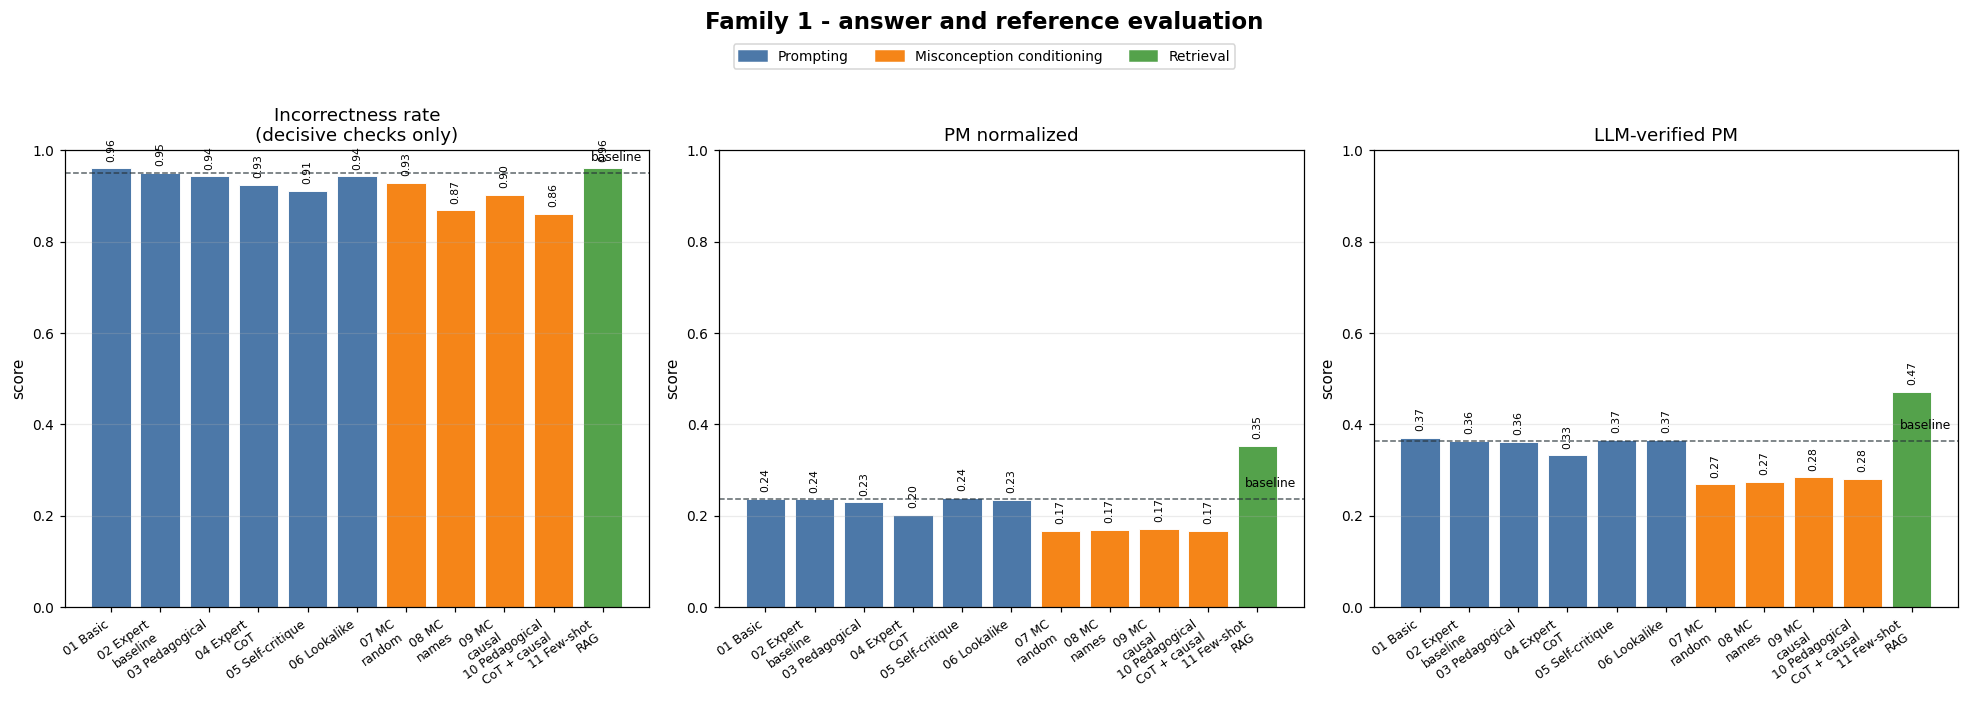

In [33]:
short_labels = {
    "01_basic_direct": "01 Basic",
    "02_expert_direct": "02 Expert\nbaseline",
    "03_pedagogical_direct": "03 Pedagogical",
    "04_expert_cot": "04 Expert\nCoT",
    "05_expert_self_critique": "05 Self-critique",
    "06_lookalike_direct": "06 Lookalike",
    "07_expert_mc_random": "07 MC\nrandom",
    "08_expert_mc_names": "08 MC\nnames",
    "09_expert_mc_causal": "09 MC\ncausal",
    "10_pedagogical_cot_mc_causal": "10 Pedagogical\nCoT + causal",
    "11_fewshot_rag": "11 Few-shot\nRAG",
}
family_by_condition = generation_df.set_index("condition")["family"].to_dict()
bar_colors = [FAMILY_COLORS[family_by_condition[condition]] for condition in CONDITIONS]
labels = [short_labels[condition] for condition in CONDITIONS]
handles = [
    plt.Rectangle((0, 0), 1, 1, color=color, label=family)
    for family, color in FAMILY_COLORS.items()
]

family1_specs = [
    ("incorrectness_rate", "Incorrectness rate\n(decisive checks only)", 1.0),
    ("PM_normalized", "PM normalized", 1.0),
    ("PM_llm", "LLM-verified PM", 1.0),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True)
for ax, (column, title, upper) in zip(axes, family1_specs):
    values = aggregate_df[column].to_numpy(dtype=float)
    bars = ax.bar(np.arange(len(CONDITIONS)), values, color=bar_colors, edgecolor="white", linewidth=0.6)
    baseline_value = float(aggregate_df.loc[aggregate_df["condition"] == "02_expert_direct", column].iloc[0])
    ax.axhline(baseline_value, color="#263238", linestyle="--", linewidth=1, alpha=0.75)
    ax.text(len(CONDITIONS) - 0.2, baseline_value + 0.02, "baseline", ha="right", va="bottom", fontsize=8)
    ax.set_title(title)
    ax.set_ylim(0, upper)
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylabel("score")
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.2f}", ha="center", va="bottom", fontsize=7, rotation=90)

for ax in axes:
    ax.set_xticks(np.arange(len(CONDITIONS)))
    ax.set_xticklabels(labels, rotation=35, ha="right")

fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Family 1 - answer and reference evaluation", fontsize=15, weight="bold", y=1.06)
plt.tight_layout()
plt.show()

## 4. Family 2: student-error and pathway evaluation

Family 2 is separate from reference matching. It asks whether a learner could plausibly produce an option and whether the claimed path is coherent and distinct.

Pathway diversity is conditional: a question-run contributes only when at least two distractors are incorrect, plausible, and coherence-passing. Runs with fewer qualifying distractors remain `not measurable` and are counted in the coverage plot.

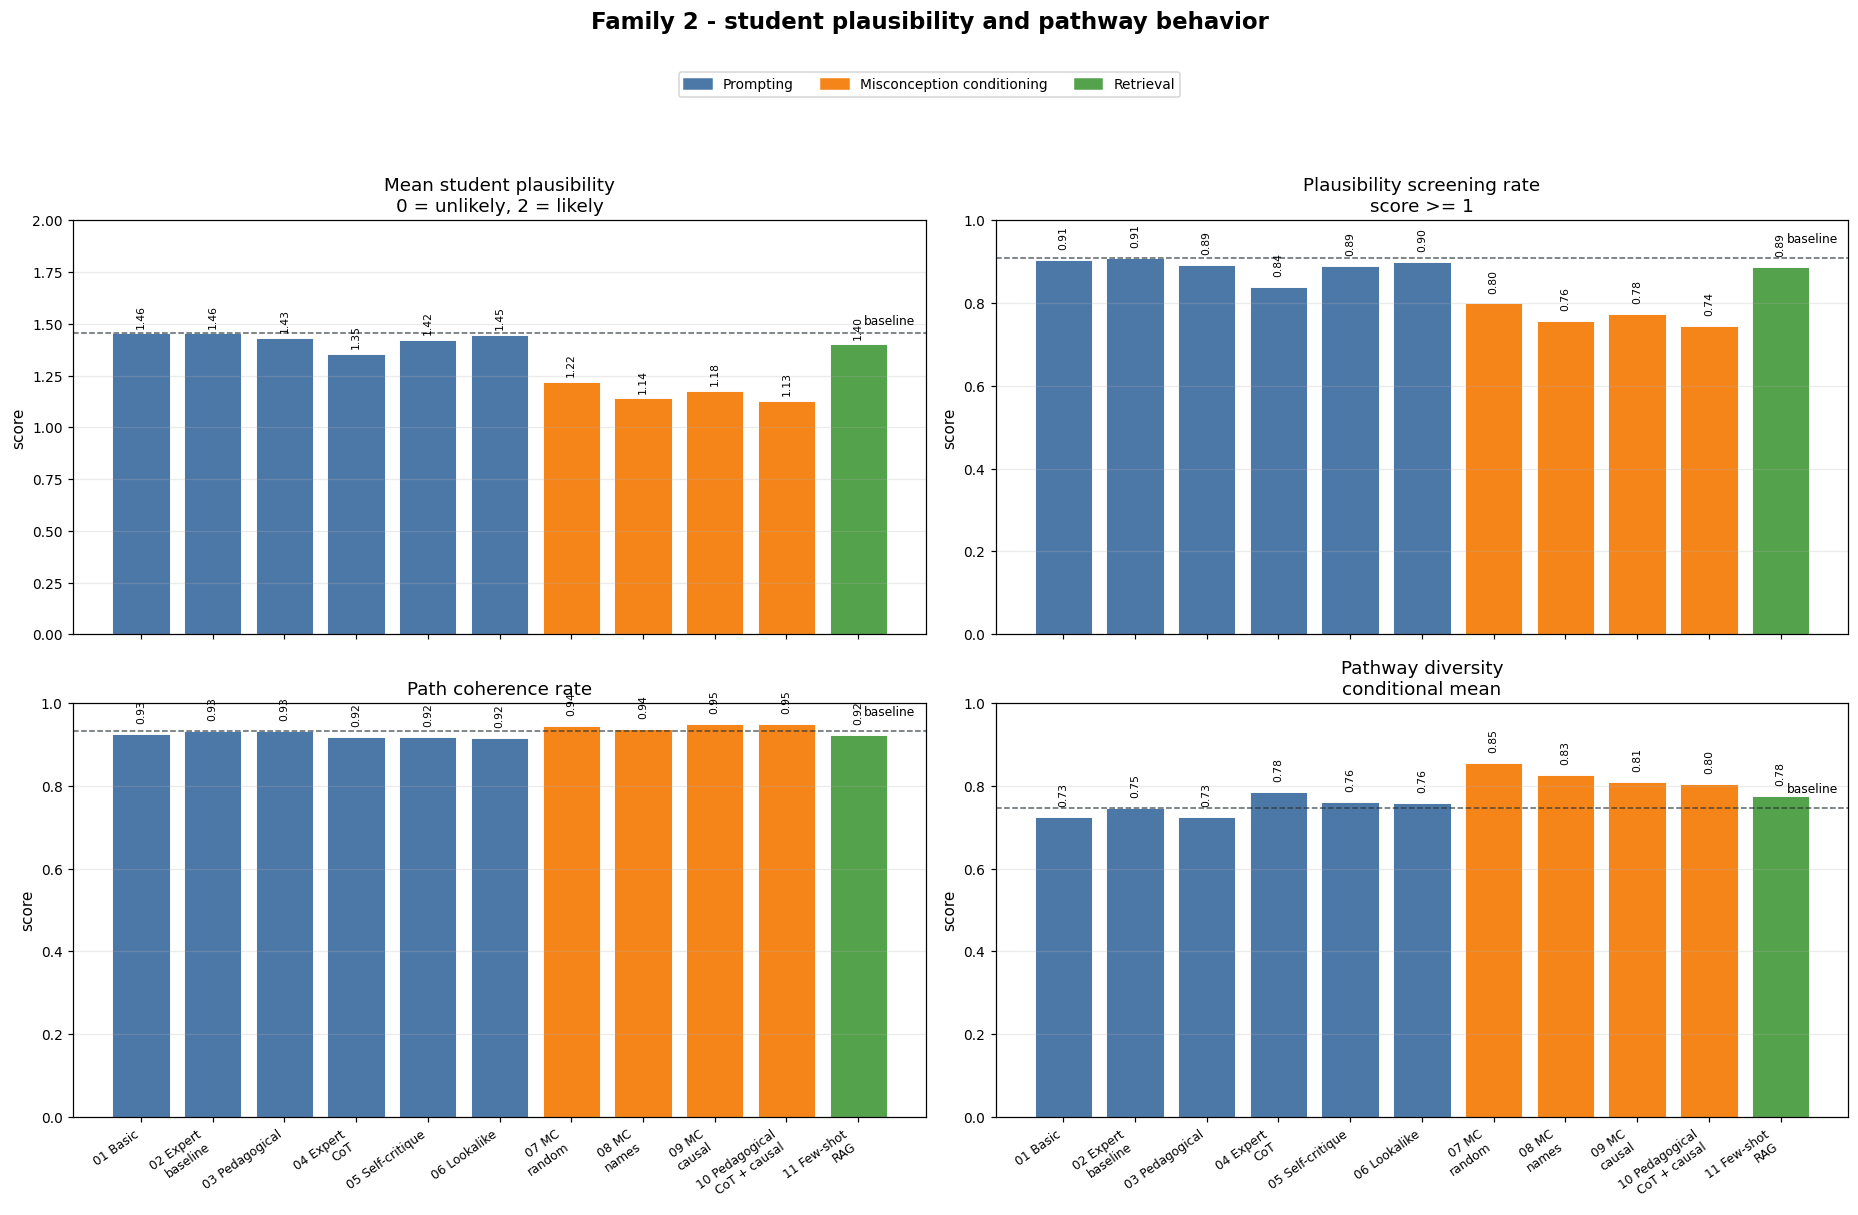

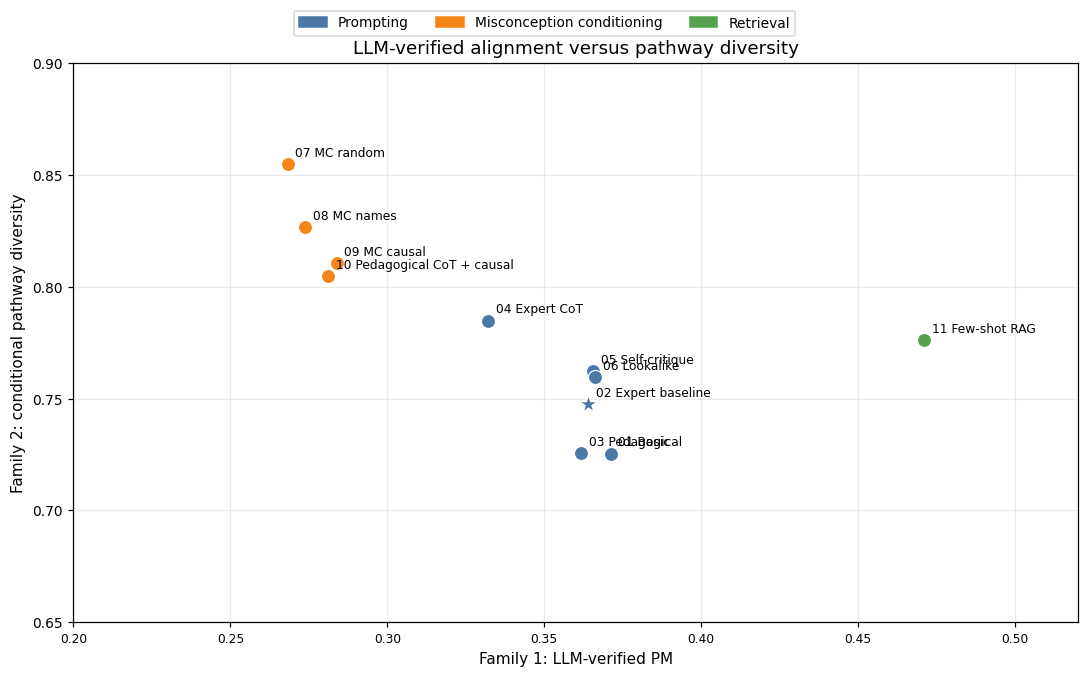

,condition,path_coherence_measured_question_runs,pathway_diversity_measured_question_runs,PM_llm_unknown_pairs
0,01_basic_direct,600,193,0
1,02_expert_direct,600,192,1
2,03_pedagogical_direct,600,184,1
3,04_expert_cot,600,179,1
4,05_expert_self_critique,600,185,0
5,06_lookalike_direct,600,185,0
6,07_expert_mc_random,600,172,4
7,08_expert_mc_names,600,153,1
8,09_expert_mc_causal,600,153,1
9,10_pedagogical_cot_mc_causal,600,151,0


In [34]:
family2_specs = [
    ("student_plausibility_mean_0_to_2", "Mean student plausibility\n0 = unlikely, 2 = likely", 2.0),
    ("student_plausibility_screening_rate_ge_1", "Plausibility screening rate\nscore >= 1", 1.0),
    ("path_coherence_rate", "Path coherence rate", 1.0),
    ("pathway_diversity_mean", "Pathway diversity\nconditional mean", 1.0),
]

fig, axes = plt.subplots(2, 2, figsize=(17, 10), sharex=True)
for ax, (column, title, upper) in zip(axes.flat, family2_specs):
    values = aggregate_df[column].to_numpy(dtype=float)
    bars = ax.bar(np.arange(len(CONDITIONS)), values, color=bar_colors, edgecolor="white", linewidth=0.6)
    baseline_value = float(aggregate_df.loc[aggregate_df["condition"] == "02_expert_direct", column].iloc[0])
    ax.axhline(baseline_value, color="#263238", linestyle="--", linewidth=1, alpha=0.75)
    ax.text(len(CONDITIONS) - 0.2, baseline_value + 0.03, "baseline", ha="right", va="bottom", fontsize=8)
    ax.set_title(title)
    ax.set_ylim(0, upper)
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylabel("score")
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.025, f"{value:.2f}", ha="center", va="bottom", fontsize=7, rotation=90)

for ax in axes[1]:
    ax.set_xticks(np.arange(len(CONDITIONS)))
    ax.set_xticklabels(labels, rotation=35, ha="right")

fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.05))
fig.suptitle("Family 2 - student plausibility and pathway behavior", fontsize=15, weight="bold", y=1.10)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for condition in CONDITIONS:
    subset = aggregate_df[aggregate_df["condition"] == condition].iloc[0]
    family = family_by_condition[condition]
    ax.scatter(
        subset["PM_llm"],
        subset["pathway_diversity_mean"],
        s=150 if condition == "02_expert_direct" else 85,
        marker="*" if condition == "02_expert_direct" else "o",
        color=FAMILY_COLORS[family],
        edgecolor="white",
        linewidth=0.8,
        zorder=3,
    )
    ax.annotate(short_labels[condition].replace("\n", " "), (subset["PM_llm"], subset["pathway_diversity_mean"]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_title("LLM-verified alignment versus pathway diversity")
ax.set_xlabel("Family 1: LLM-verified PM")
ax.set_ylabel("Family 2: conditional pathway diversity")
ax.set_xlim(0.20, 0.52)
ax.set_ylim(0.65, 0.90)
ax.grid(alpha=0.25)
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()
plt.show()

display(aggregate_df[[
    "condition", "path_coherence_measured_question_runs",
    "pathway_diversity_measured_question_runs", "PM_llm_unknown_pairs",
]])

## 5. What the complete structured evaluation says - descriptively

### Family 1: answer and reference evaluation

- **Few-shot RAG remains strongest for reference alignment:** `11_fewshot_rag` reaches PM normalized `0.353` and LLM-verified PM `0.471`, compared with `0.236` and `0.364` for the expert-direct baseline.
- **LLM-verified PM is more permissive than deterministic normalized PM:** it judges semantic answer equivalence in context, so it is secondary evidence and retains unknown pair counts rather than replacing deterministic PM.
- **Incorrectness is conservative:** unsupported symbolic or text answers remain `unknown`, while decisive answers are evaluated as correct or incorrect. The notebook does not plot a separate incorrectness-coverage metric.

### Family 2: student-error and pathway evaluation

- **Expert-direct plausibility:** mean `1.455 / 2`, with `0.909` passing the broad `score >= 1` screen.
- **RAG plausibility:** mean `1.402 / 2`, with `0.888` passing the screen. RAG improves alignment but is not automatically more plausible.
- **Path coherence is high but not perfect:** the expert-direct baseline reaches `0.932`; conditions range from about `0.916` to `0.950`.
- **Pathway diversity is measurable conditionally:** expert-direct averages `0.747` over 192 measured question-runs; MC random reaches `0.855`, while RAG reaches `0.776`. Measurement coverage remains available in the summary table, but is not treated as a quality score.
- **CoT is weaker on plausibility but can show higher conditional pathway diversity:** `04_expert_cot` has plausibility `1.354 / 2` and pathway diversity `0.785` over 179 measured question-runs. This is not evidence that CoT is better overall.

### Interpretation limits

These are descriptive means from the complete structured evaluation. The final source has 6,600 unique structured records, all with required `faulty_step` and `reasoning_steps`. The pathway metric is a judge over generator-supplied paths, not real-student behavior, and the functional-diversity instrument was not run here. The notebook does not perform bootstrap intervals, hypothesis tests, or multiple-comparison correction.